# Week 6 Term Project Milestone 1: Data Selection and EDA

**Title:** Predicting Low Customer Review Scores in E-Commerce Orders  
**Student:** Adam A. Saenz  
**Assignment:** Milestone 1 – Data Selection and Exploratory Data Analysis (EDA)

---

## Business Problem Narrative

In business, it's widly understood that customer satisfaction is the greatest driver of retention, repeat purchases and brand reputation in e-commerce. When customers have poor delivery experiences or fulfillment delays, they're more likely to leave negative reviews. For a company operating an online marketplace, identifying the factors that contribute to low review scores can help improve logistics and customer experience. Solving this problem has clear business value because higher customer satisfaction can reduce churn and support revenue growth. The project that I present analyzes e-commerce order data to better understand what factors are associated with negative customer reviews. The business problem being addressed is: How can an online marketplace identify orders that are most likely to receive a low review score so that it can reduce customer dissatisfaction? The target for the future model is a binary variable called `low_review`, where orders with a review score of 1 or 2 are labeled as low reviews and all other reviewed orders are labeled as not low. This turns the problem into a supervised classification problem that can support future predictive modeling.

The dataset selected for this project is the Brazilian E-Commerce Public Dataset by Olist from Kaggle. I believve that it's well suited for the assignment because it includes multiple connected tables containing customer, order, item, payment, product, seller and review information. These linked tables allow for a realistic business analysis rather than a simple toy example. Key variables such as order status, freight value, price, delivery timing, product category, payment installments and customer review score make it possible to explore both operational and customer-experience factors. This milestone focuses on exploratory data analysis and graphical analysis to understand the structure of the data and identify early patterns. The visualizations below examine review scores, delivery delays, payment behavior and product-category performance. These findings will help guide feature selection and model design in the next stage of the project. This analysis is intended to support a business decision-making process that can improve delivery outcomes and customer satisfaction.

## Selected Dataset and Rationale

**Primary dataset:** Brazilian E-Commerce Public Dataset by Olist

**Files used in this notebook:**
- `olist_orders_dataset.csv`
- `olist_order_reviews_dataset.csv`
- `olist_order_items_dataset.csv`
- `olist_order_payments_dataset.csv`
- `olist_products_dataset.csv`
- `product_category_name_translation.csv`

### Why this dataset is a strong fit
1. It addresses a real business problem with clear operational value.
2. It contains a natural target variable through the customer `review_score`.
3. It supports later machine learning work through a realistic relational structure.
4. It includes enough rows and business attributes for meaningful EDA.
5. It allows business-focused analysis of delivery, cost, and customer satisfaction.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings for cleaner notebook output
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

In [2]:
# Load the Olist data files from the same folder as this notebook

orders = pd.read_csv('olist_orders_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
category_translation = pd.read_csv('product_category_name_translation.csv')

# Optional supporting datasets for future milestones
# These are loaded only if they are in the same folder.
try:
    customers = pd.read_csv('olist_customers_dataset.csv')
    sellers = pd.read_csv('olist_sellers_dataset.csv')
    print("customers:", customers.shape)
    print("sellers:", sellers.shape)
except FileNotFoundError:
    print("Optional customer or seller files not found. Continuing without them.")

print("orders:", orders.shape)
print("reviews:", reviews.shape)
print("items:", items.shape)
print("payments:", payments.shape)
print("products:", products.shape)
print("category_translation:", category_translation.shape)

customers: (99441, 5)
sellers: (3095, 4)
orders: (99441, 8)
reviews: (99224, 7)
items: (112650, 7)
payments: (103886, 5)
products: (32951, 9)
category_translation: (71, 2)


In [3]:
# Preview source tables
display(orders.head())
display(reviews.head())
display(items.head())
display(payments.head())
display(products.head())
display(category_translation.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


## Data Preparation

The Olist dataset is stored in multiple related tables, so the first step is to combine the tables needed for the milestone analysis. This notebook creates an order-level dataset by joining orders, reviews, aggregated order-item values, aggregated payment information and product category information.

Because some tables operate at the item level rather than the order level, they must first be aggregated to avoid duplication during the merges.

In [4]:
# Convert relevant date columns to datetime
date_cols_orders = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols_orders:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

reviews["review_creation_date"] = pd.to_datetime(reviews["review_creation_date"], errors="coerce")
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"], errors="coerce")

In [5]:
# Merge products with the English category name translation table
products = products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

display(products.head())

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,housewares


In [6]:
# Aggregate item-level data up to the order level
items_agg = (
    items.groupby("order_id", as_index=False)
         .agg(
             total_price=("price", "sum"),
             total_freight=("freight_value", "sum"),
             item_count=("order_item_id", "count")
         )
)

# Aggregate payment data up to the order level
payments_agg = (
    payments.groupby("order_id", as_index=False)
            .agg(
                payment_value=("payment_value", "sum"),
                payment_installments=("payment_installments", "max")
            )
)

# Attach category names to items, then capture one representative English category per order
items_products = items.merge(
    products[["product_id", "product_category_name_english"]],
    on="product_id",
    how="left"
)

category_agg = (
    items_products.groupby("order_id")["product_category_name_english"]
                  .agg(lambda x: x.dropna().iloc[0] if len(x.dropna()) > 0 else np.nan)
                  .reset_index()
)

In [7]:
# Build the order-level analytical dataset
df = (
    orders.merge(reviews[["order_id", "review_score"]], on="order_id", how="left")
          .merge(items_agg, on="order_id", how="left")
          .merge(payments_agg, on="order_id", how="left")
          .merge(category_agg, on="order_id", how="left")
)

# Create engineered features for EDA and future modeling
df["days_to_deliver"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days
df["estimated_days"] = (df["order_estimated_delivery_date"] - df["order_purchase_timestamp"]).dt.days
df["delivery_delay_days"] = (df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]).dt.days
df["delivery_delay_days"] = df["delivery_delay_days"].fillna(0)
df["is_late"] = np.where(df["delivery_delay_days"] > 0, 1, 0)
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["low_review"] = np.where(df["review_score"].isin([1, 2]), 1, 0)

# Keep only observations with review scores for this milestone
eda_df = df[df["review_score"].notna()].copy()

print("Final EDA dataset shape:", eda_df.shape)
display(eda_df.head())

Final EDA dataset shape: (99224, 21)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,review_score,total_price,total_freight,item_count,payment_value,payment_installments,product_category_name_english,days_to_deliver,estimated_days,delivery_delay_days,is_late,purchase_month,low_review
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,4.0,29.99,8.72,1.0,38.71,1.0,housewares,8.0,15,-8.0,0,2017-10,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,4.0,118.70,22.76,1.0,141.46,1.0,perfumery,13.0,19,-6.0,0,2018-07,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,5.0,159.90,19.22,1.0,179.12,3.0,auto,9.0,26,-18.0,0,2018-08,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,5.0,45.00,27.20,1.0,72.20,1.0,pet_shop,13.0,26,-13.0,0,2017-11,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,5.0,19.90,8.72,1.0,28.62,1.0,stationery,2.0,12,-10.0,0,2018-02,0


In [8]:
# Review missing values in the EDA dataset
missing_summary = eda_df.isna().sum().sort_values(ascending=False)
display(missing_summary[missing_summary > 0])

order_delivered_customer_date    2865
days_to_deliver                  2865
product_category_name_english    2168
order_delivered_carrier_date     1756
total_freight                     759
total_price                       759
item_count                        759
order_approved_at                 156
payment_value                       1
payment_installments                1
dtype: int64

## Initial Observations

The merged dataset now contains operational, payment and review information at the order level. This structure is appropriate for exploratory analysis and later machine learning because each row represents one business event: a customer order. The variables created above also establish a strong foundation for modeling customer dissatisfaction through delivery timing, cost and order complexity.

## Graph 1: Distribution of Customer Review Scores

This visualization shows how customers rated their orders. It helps determine whether the target variable is balanced and whether most customer experiences were positive or negative.

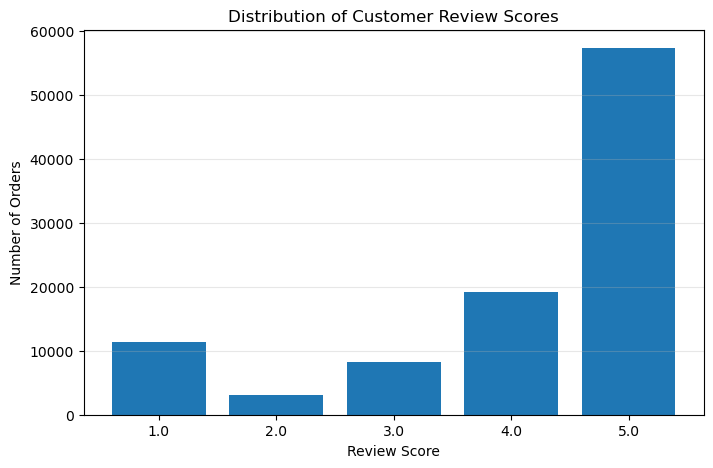

review_score
1.0    11424
2.0     3151
3.0     8179
4.0    19142
5.0    57328
Name: count, dtype: int64


In [9]:
review_counts = eda_df["review_score"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(review_counts.index.astype(str), review_counts.values)
plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Orders")
plt.grid(axis="y", alpha=0.3)
plt.show()

print(review_counts)

**Analysis of Graph 1:**  
The distribution of review scores helps show whether customer satisfaction is concentrated at the high end or spread more evenly across all scores. If 4-star and 5-star reviews dominate, that means the future target class for low reviews is imbalanced, which will matter during model development. Even so, the low-score observations remain highly important because they represent dissatisfied customers and potentially costly service failures.

## Graph 2: Average Review Score by Delivery Status

This graph compares the average review score for orders delivered on time versus late orders. This relationship is important because delayed delivery is a plausible driver of customer dissatisfaction.

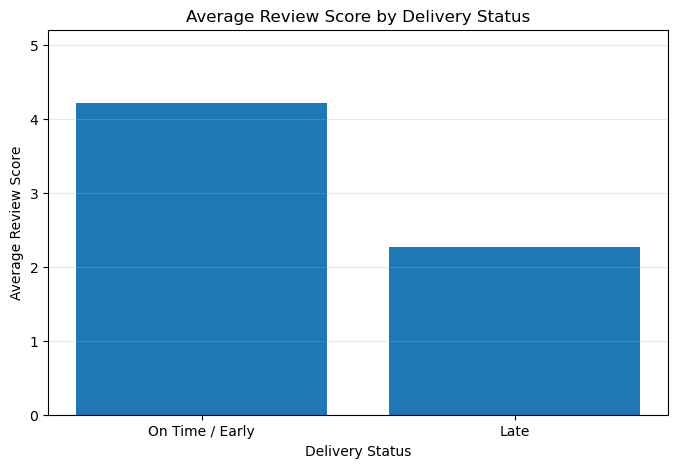

,is_late,review_score,delivery_status
0,0,4.211789,On Time / Early
1,1,2.271139,Late


In [10]:
late_review = eda_df.groupby("is_late", as_index=False)["review_score"].mean()
late_review["delivery_status"] = late_review["is_late"].map({0: "On Time / Early", 1: "Late"})

plt.figure(figsize=(8, 5))
plt.bar(late_review["delivery_status"], late_review["review_score"])
plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Average Review Score")
plt.ylim(0, 5.2)
plt.grid(axis="y", alpha=0.3)
plt.show()

display(late_review)

**Analysis of Graph 2:**  
This graph begins to answer whether delivery delays are associated with lower customer satisfaction. If late deliveries show a meaningfully lower average review score than on-time deliveries, that suggests logistics performance is a useful predictor for the future classification model. From a business perspective, this would support process improvements in shipping speed and fulfillment reliability.

## Graph 3: Payment Value vs Review Score

This scatter plot explores whether higher-value orders are associated with different customer review outcomes. It helps assess whether spending level appears related to satisfaction.

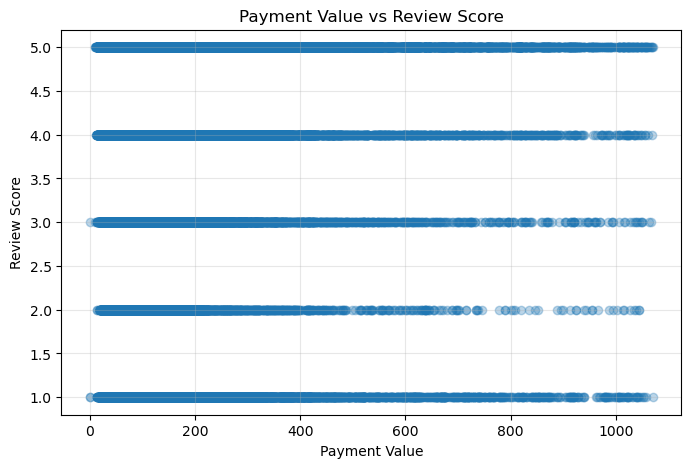

In [11]:
plot_df = eda_df[["payment_value", "review_score"]].dropna().copy()

# Limit extreme outliers so the main relationship is easier to see
plot_df = plot_df[plot_df["payment_value"] < plot_df["payment_value"].quantile(0.99)]

plt.figure(figsize=(8, 5))
plt.scatter(plot_df["payment_value"], plot_df["review_score"], alpha=0.3)
plt.title("Payment Value vs Review Score")
plt.xlabel("Payment Value")
plt.ylabel("Review Score")
plt.grid(alpha=0.3)
plt.show()

**Analysis of Graph 3:**  
This figure evaluates whether expensive orders tend to receive better or worse reviews. A weak relationship would suggest that order value alone does not explain customer satisfaction very well, while any visible clustering or trend could indicate that higher-value transactions come with different customer expectations. This graph is useful because it separates operational issues from pure spending behavior.

## Graph 4: Average Review Score for the Top 10 Product Categories

This graph compares customer review performance across the ten most common product categories in the data. Using English category names makes the business interpretation much clearer.

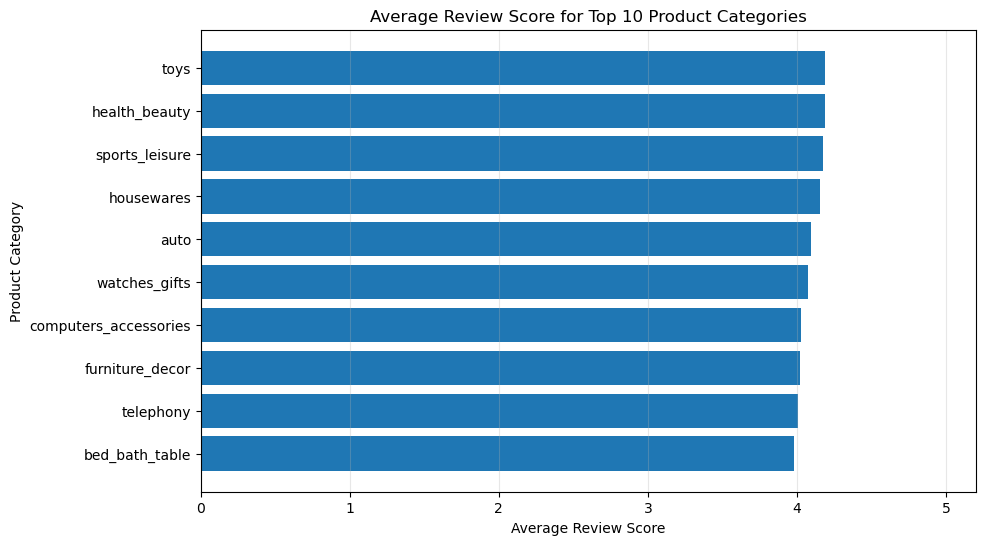

,product_category_name_english,review_score
1,bed_bath_table,3.979522
7,telephony,4.007940
3,furniture_decor,4.020591
2,computers_accessories,4.027420
9,watches_gifts,4.071172
0,auto,4.095152
5,housewares,4.151625
6,sports_leisure,4.173109
4,health_beauty,4.187344
8,toys,4.189732


In [12]:
top_categories = eda_df["product_category_name_english"].value_counts().head(10).index

cat_review = (
    eda_df[eda_df["product_category_name_english"].isin(top_categories)]
    .groupby("product_category_name_english", as_index=False)["review_score"].mean()
    .sort_values("review_score", ascending=True)
)

plt.figure(figsize=(10, 6))
plt.barh(cat_review["product_category_name_english"], cat_review["review_score"])
plt.title("Average Review Score for Top 10 Product Categories")
plt.xlabel("Average Review Score")
plt.ylabel("Product Category")
plt.xlim(0, 5.2)
plt.grid(axis="x", alpha=0.3)
plt.show()

display(cat_review)

**Analysis of Graph 4:**  
Differences in average review score across product categories can reveal where customer experience problems are concentrated. Lower-performing categories may reflect product-quality issues, seller-related problems or fulfillment challenges. These patterns can later become predictive features or support business recommendations focused on category-level improvement.

## Graph 5: Low Review Rate by Delivery Status

This final graph directly connects the business problem to the future model target. It compares the proportion of low reviews for late and on-time deliveries.

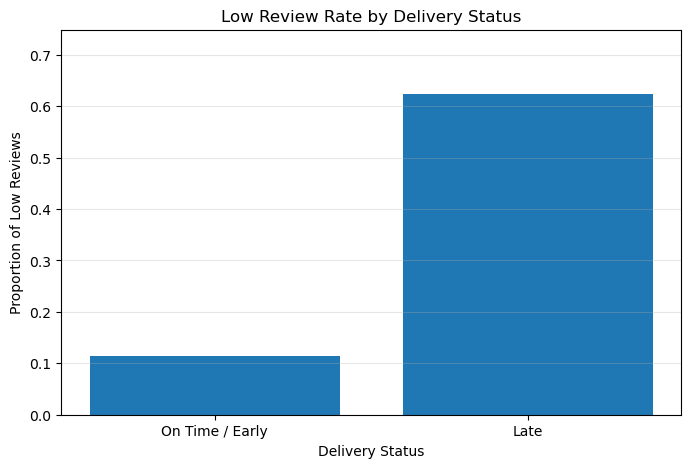

,is_late,low_review,delivery_status
0,0,0.113938,On Time / Early
1,1,0.624025,Late


In [13]:
delay_group = eda_df.groupby("is_late", as_index=False)["low_review"].mean()
delay_group["delivery_status"] = delay_group["is_late"].map({0: "On Time / Early", 1: "Late"})

plt.figure(figsize=(8, 5))
plt.bar(delay_group["delivery_status"], delay_group["low_review"])
plt.title("Low Review Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Proportion of Low Reviews")
plt.ylim(0, max(delay_group["low_review"]) * 1.2)
plt.grid(axis="y", alpha=0.3)
plt.show()

display(delay_group)

**Analysis of Graph 5:**  
This graph is crucial because it directly measures the target behavior of interest. If late deliveries have a noticeably higher proportion of low reviews, then delivery timing isn't just associated with average satisfaction, but specifically with negative customer outcomes. This strengthens the business case for using delivery-related features in the future predictive model.

## Optional Supporting Table

The table below summarizes the percentage of low-review orders. This helps define the future modeling target and provides an early view of class balance.

In [14]:
target_summary = eda_df["low_review"].value_counts(normalize=True).rename("proportion").reset_index()
target_summary.columns = ["low_review", "proportion"]
target_summary["low_review"] = target_summary["low_review"].map({0: "Not Low Review", 1: "Low Review"})
display(target_summary)

,low_review,proportion
0,Not Low Review,0.85311
1,Low Review,0.14689


## Conclusion

The exploratory analysis reveals that customer dissatisfaction is associated with operational factors, particularly delivery performance. Orders that are delivered late usually show lower average review scores and a higher likelihood of negative feedback. This indicates that logistics and fulfillment efficiency are key drivers of customer experience. Variation across product categories suggests that certain segments of the marketplace may face higher risk of dissatisfaction, potentially due to product quality or fulfillment complexity. By comparison, payment value alone doesn't appear to influence review outcomes, reinforcing that operational execution is more impactful than transaction size. My findings support the development of a predictive model focused on identifying orders at risk of receiving low review scores. A model like this would enable proactive intervention strategies, like prioritizing at-risk shipments, ultimately enhancing customer satisfaction and reducing negative reviews.

## References

Ahmed, S. (2024). *Building your first machine learning project: A beginner’s guide*. Medium.

Ng, A. (2019). *How to choose your first AI project*. Harvard Business Review.

Olist. (n.d.). *Brazilian E-Commerce Public Dataset by Olist*. Kaggle.


# Milestone 2 – Data Preparation and Feature Engineering

## Overview

The purpose of Milestone 2 is to prepare the dataset for machine learning model development. This stage focuses on:

- Creating a target variable
- Preventing data leakage
- Engineering useful predictive features
- Handling missing data
- Transforming variables
- Creating dummy variables
- Preparing the dataset for model training

My goal for this project is to predict whether a customer is likely to leave a low review score for an e-commerce order.



## Step 1: Create the Target Variable

The original `review_score` variable contains ratings from 1 to 5. For this project, the review score is transformed into a binary classification target variable called `low_review`.

- Reviews of 1 or 2 are considered low reviews
- Reviews of 3, 4, and 5 are considered non-low reviews

This transformation converts the problem into a binary classification problem suitable for machine learning models.


In [15]:

# Create binary target variable
eda_df["low_review"] = np.where(eda_df["review_score"] <= 2, 1, 0)

# Review class balance
eda_df["low_review"].value_counts()


low_review
0    84649
1    14575
Name: count, dtype: int64


## Step 2: Feature Engineering

Feature engineering helps create more meaningful variables from the original data. Several new variables were created to better represent operational performance and customer experience.

These engineered features include:

- Shipping duration
- Delivery delays
- Purchase month
- Purchase day of week
- Average item price
- Freight-to-price ratio

These variables may improve the predictive performance of future machine learning models.


In [16]:

# Create shipping duration feature
eda_df["shipping_days"] = (
    eda_df["order_delivered_customer_date"] -
    eda_df["order_purchase_timestamp"]
).dt.days

# Create delivery delay feature
eda_df["delivery_delay_days"] = (
    eda_df["order_delivered_customer_date"] -
    eda_df["order_estimated_delivery_date"]
).dt.days

# Create purchase month feature
eda_df["purchase_month"] = (
    eda_df["order_purchase_timestamp"].dt.month
)

# Create purchase day of week feature
eda_df["purchase_dayofweek"] = (
    eda_df["order_purchase_timestamp"].dt.day_name()
)

# Create average price per item feature
eda_df["avg_price_per_item"] = (
    eda_df["total_price"] / eda_df["item_count"]
)

# Create freight ratio feature
eda_df["freight_ratio"] = (
    eda_df["total_freight"] / eda_df["total_price"]
)

# Preview engineered features
eda_df[[
    "shipping_days",
    "delivery_delay_days",
    "purchase_month",
    "purchase_dayofweek",
    "avg_price_per_item",
    "freight_ratio"
]].head()


,shipping_days,delivery_delay_days,purchase_month,purchase_dayofweek,avg_price_per_item,freight_ratio
0,8.0,-8.0,10,Monday,29.99,0.290764
1,13.0,-6.0,7,Tuesday,118.70,0.191744
2,9.0,-18.0,8,Wednesday,159.90,0.120200
3,13.0,-13.0,11,Saturday,45.00,0.604444
4,2.0,-10.0,2,Tuesday,19.90,0.438191



## Step 3: Handle Missing Data

Missing data was reviewed carefully before preparing the dataset for modeling. Instead of immediately dropping rows or columns, missing values were handled differently depending on the variable type.

- Numeric columns were filled using the median value
- Categorical columns were filled using the label `Unknown`

This approach preserves observations while reducing the impact of missing values on future models.


In [17]:

# Review missing values before cleaning
missing_before = eda_df.isnull().sum().sort_values(ascending=False)

display(missing_before[missing_before > 0].head(20))


shipping_days                    2865
order_delivered_customer_date    2865
delivery_delay_days              2865
days_to_deliver                  2865
product_category_name_english    2168
order_delivered_carrier_date     1756
freight_ratio                     759
avg_price_per_item                759
total_price                       759
total_freight                     759
item_count                        759
order_approved_at                 156
payment_installments                1
payment_value                       1
dtype: int64

In [18]:

# Fill numeric missing values with median
numeric_cols = eda_df.select_dtypes(include=["int64", "float64"]).columns

for col in numeric_cols:
    eda_df[col] = eda_df[col].fillna(eda_df[col].median())

# Fill categorical missing values with 'Unknown'
categorical_cols = eda_df.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    eda_df[col] = eda_df[col].fillna("Unknown")

# Verify missing values after cleaning
missing_after = eda_df.isnull().sum().sum()

print("Total Remaining Missing Values:", missing_after)


Total Remaining Missing Values: 4777



## Step 4: Drop Features That Could Cause Data Leakage

Some columns were removed because they could introduce data leakage or would not realistically be available when making future predictions.

Examples include:

- Unique identifiers
- Review text fields
- Review timestamps
- Raw datetime variables after feature engineering

Removing these variables helps improve model fairness and prevents unrealistic model performance.


In [19]:

# Columns to remove
cols_to_drop = [
    "order_id",
    "customer_id",
    "review_id",
    "review_comment_title",
    "review_comment_message",
    "review_creation_date",
    "review_answer_timestamp",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Drop columns if they exist
model_df = eda_df.drop(columns=cols_to_drop, errors="ignore")

# Preview updated dataframe
model_df.head()


,order_status,review_score,total_price,total_freight,item_count,payment_value,payment_installments,product_category_name_english,days_to_deliver,estimated_days,delivery_delay_days,is_late,purchase_month,low_review,shipping_days,purchase_dayofweek,avg_price_per_item,freight_ratio
0,delivered,4.0,29.99,8.72,1.0,38.71,1.0,housewares,8.0,15,-8.0,0,10,0,8.0,Monday,29.99,0.290764
1,delivered,4.0,118.70,22.76,1.0,141.46,1.0,perfumery,13.0,19,-6.0,0,7,0,13.0,Tuesday,118.70,0.191744
2,delivered,5.0,159.90,19.22,1.0,179.12,3.0,auto,9.0,26,-18.0,0,8,0,9.0,Wednesday,159.90,0.120200
3,delivered,5.0,45.00,27.20,1.0,72.20,1.0,pet_shop,13.0,26,-13.0,0,11,0,13.0,Saturday,45.00,0.604444
4,delivered,5.0,19.90,8.72,1.0,28.62,1.0,stationery,2.0,12,-10.0,0,2,0,2.0,Tuesday,19.90,0.438191



## Step 5: Create Dummy Variables

Machine learning algorithms cannot directly process text-based categorical variables. Important categorical features were converted into dummy variables using one-hot encoding.

This process allows categorical information to be represented numerically without implying an ordinal relationship between categories.


In [20]:
# Check available columns first
print(model_df.columns.tolist())

# Select only columns that actually exist
dummy_cols = []

possible_cols = [
    "order_status",
    "payment_type",
    "purchase_dayofweek",
    "product_category_name_english"
]

for col in possible_cols:
    if col in model_df.columns:
        dummy_cols.append(col)

print("Columns being encoded:")
print(dummy_cols)

# Create dummy variables
model_df = pd.get_dummies(
    model_df,
    columns=dummy_cols,
    drop_first=True
)

# Preview dataframe
model_df.head()


['order_status', 'review_score', 'total_price', 'total_freight', 'item_count', 'payment_value', 'payment_installments', 'product_category_name_english', 'days_to_deliver', 'estimated_days', 'delivery_delay_days', 'is_late', 'purchase_month', 'low_review', 'shipping_days', 'purchase_dayofweek', 'avg_price_per_item', 'freight_ratio']
Columns being encoded:
['order_status', 'purchase_dayofweek', 'product_category_name_english']


,review_score,total_price,total_freight,item_count,payment_value,payment_installments,days_to_deliver,estimated_days,delivery_delay_days,is_late,purchase_month,low_review,shipping_days,avg_price_per_item,freight_ratio,order_status_canceled,order_status_created,order_status_delivered,order_status_invoiced,order_status_processing,order_status_shipped,order_status_unavailable,purchase_dayofweek_Monday,purchase_dayofweek_Saturday,purchase_dayofweek_Sunday,purchase_dayofweek_Thursday,purchase_dayofweek_Tuesday,purchase_dayofweek_Wednesday,product_category_name_english_agro_industry_and_commerce,product_category_name_english_air_conditioning,product_category_name_english_art,product_category_name_english_arts_and_craftmanship,product_category_name_english_audio,product_category_name_english_auto,product_category_name_english_baby,product_category_name_english_bed_bath_table,product_category_name_english_books_general_interest,product_category_name_english_books_imported,product_category_name_english_books_technical,product_category_name_english_cds_dvds_musicals,product_category_name_english_christmas_supplies,product_category_name_english_cine_photo,product_category_name_english_computers,product_category_name_english_computers_accessories,product_category_name_english_consoles_games,product_category_name_english_construction_tools_construction,product_category_name_english_construction_tools_lights,product_category_name_english_construction_tools_safety,product_category_name_english_cool_stuff,product_category_name_english_costruction_tools_garden,product_category_name_english_costruction_tools_tools,product_category_name_english_diapers_and_hygiene,product_category_name_english_drinks,product_category_name_english_dvds_blu_ray,product_category_name_english_electronics,product_category_name_english_fashio_female_clothing,product_category_name_english_fashion_bags_accessories,product_category_name_english_fashion_childrens_clothes,product_category_name_english_fashion_male_clothing,product_category_name_english_fashion_shoes,product_category_name_english_fashion_sport,product_category_name_english_fashion_underwear_beach,product_category_name_english_fixed_telephony,product_category_name_english_flowers,product_category_name_english_food,product_category_name_english_food_drink,product_category_name_english_furniture_bedroom,product_category_name_english_furniture_decor,product_category_name_english_furniture_living_room,product_category_name_english_furniture_mattress_and_upholstery,product_category_name_english_garden_tools,product_category_name_english_health_beauty,product_category_name_english_home_appliances,product_category_name_english_home_appliances_2,product_category_name_english_home_comfort_2,product_category_name_english_home_confort,product_category_name_english_home_construction,product_category_name_english_housewares,product_category_name_english_industry_commerce_and_business,product_category_name_english_kitchen_dining_laundry_garden_furniture,product_category_name_english_la_cuisine,product_category_name_english_luggage_accessories,product_category_name_english_market_place,product_category_name_english_music,product_category_name_english_musical_instruments,product_category_name_english_office_furniture,product_category_name_english_party_supplies,product_category_name_english_perfumery,product_category_name_english_pet_shop,product_category_name_english_security_and_services,product_category_name_english_signaling_and_security,product_category_name_english_small_appliances,product_category_name_english_small_appliances_home_oven_and_coffee,product_category_name_english_sports_leisure,product_category_name_english_stationery,product_category_name_english_tablets_printing_image,product_category_name_english_telephony,product_category_name_english_toys,product_category_name_english_watches_gifts
0,4.0,29.99,8.72,1.0,38.71,1.0,8.0,15,-8.0,0,10,0,8.0,29.99,0.290764,False,False,True,False,False,False,False,True,Fal


## Step 6: Scale Numeric Features

Several numeric variables were standardized using `StandardScaler`. Standardization places variables on similar scales and helps prevent large numeric values from disproportionately influencing machine learning algorithms.

This is especially important for models such as:

- Logistic Regression
- K-Nearest Neighbors
- Neural Networks


In [21]:

from sklearn.preprocessing import StandardScaler

# Numeric columns selected for scaling
scale_cols = [
    "total_price",
    "total_freight",
    "payment_value",
    "item_count",
    "shipping_days",
    "delivery_delay_days",
    "avg_price_per_item",
    "freight_ratio"
]

# Initialize scaler
scaler = StandardScaler()

# Scale selected columns
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

# Preview scaled data
model_df[scale_cols].head()


,total_price,total_freight,payment_value,item_count,shipping_days,delivery_delay_days,avg_price_per_item,freight_ratio
0,-0.513526,-0.652332,-0.553091,-0.262925,-0.428590,0.393319,-0.504719,-0.054819
1,-0.087789,0.000175,-0.086711,-0.262925,0.107214,0.593983,-0.034480,-0.370561
2,0.109938,-0.164346,0.084227,-0.262925,-0.321429,-0.610002,0.183916,-0.598691
3,-0.441490,0.206524,-0.401080,-0.262925,0.107214,-0.108342,-0.425153,0.945409
4,-0.561950,-0.652332,-0.598889,-0.262925,-1.071554,0.192655,-0.558205,0.415280



## Step 7: Prepare Data for Modeling

The dataset is separated into:

- Feature variables (`X`)
- Target variable (`y`)

An 80/20 train-test split is used to prepare the data for future machine learning model development.

Stratified sampling preserves the distribution of low-review observations across both datasets.


In [22]:

from sklearn.model_selection import train_test_split

# Define features and target
X = model_df.drop(columns=["review_score", "low_review"])
y = model_df["low_review"]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)


X_train shape: (79379, 97)
X_test shape: (19845, 97)
y_train shape: (79379,)
y_test shape: (19845,)



## Step 8: Final Dataset Review

Before beginning model development, the final dataset was reviewed to confirm:

- Missing values were addressed
- Data leakage variables were removed
- Features were transformed appropriately
- Categorical variables were encoded
- The target variable was created successfully

The dataset is now prepared for the machine learning model-building phase.


In [23]:

# Final dataset review
print("Final Dataset Shape:", model_df.shape)

print("\nRemaining Missing Values:")
print(model_df.isnull().sum().sum())

print("\nDataset Preview:")
display(model_df.head())


Final Dataset Shape: (99224, 99)

Remaining Missing Values:
0

Dataset Preview:


,review_score,total_price,total_freight,item_count,payment_value,payment_installments,days_to_deliver,estimated_days,delivery_delay_days,is_late,purchase_month,low_review,shipping_days,avg_price_per_item,freight_ratio,order_status_canceled,order_status_created,order_status_delivered,order_status_invoiced,order_status_processing,order_status_shipped,order_status_unavailable,purchase_dayofweek_Monday,purchase_dayofweek_Saturday,purchase_dayofweek_Sunday,purchase_dayofweek_Thursday,purchase_dayofweek_Tuesday,purchase_dayofweek_Wednesday,product_category_name_english_agro_industry_and_commerce,product_category_name_english_air_conditioning,product_category_name_english_art,product_category_name_english_arts_and_craftmanship,product_category_name_english_audio,product_category_name_english_auto,product_category_name_english_baby,product_category_name_english_bed_bath_table,product_category_name_english_books_general_interest,product_category_name_english_books_imported,product_category_name_english_books_technical,product_category_name_english_cds_dvds_musicals,product_category_name_english_christmas_supplies,product_category_name_english_cine_photo,product_category_name_english_computers,product_category_name_english_computers_accessories,product_category_name_english_consoles_games,product_category_name_english_construction_tools_construction,product_category_name_english_construction_tools_lights,product_category_name_english_construction_tools_safety,product_category_name_english_cool_stuff,product_category_name_english_costruction_tools_garden,product_category_name_english_costruction_tools_tools,product_category_name_english_diapers_and_hygiene,product_category_name_english_drinks,product_category_name_english_dvds_blu_ray,product_category_name_english_electronics,product_category_name_english_fashio_female_clothing,product_category_name_english_fashion_bags_accessories,product_category_name_english_fashion_childrens_clothes,product_category_name_english_fashion_male_clothing,product_category_name_english_fashion_shoes,product_category_name_english_fashion_sport,product_category_name_english_fashion_underwear_beach,product_category_name_english_fixed_telephony,product_category_name_english_flowers,product_category_name_english_food,product_category_name_english_food_drink,product_category_name_english_furniture_bedroom,product_category_name_english_furniture_decor,product_category_name_english_furniture_living_room,product_category_name_english_furniture_mattress_and_upholstery,product_category_name_english_garden_tools,product_category_name_english_health_beauty,product_category_name_english_home_appliances,product_category_name_english_home_appliances_2,product_category_name_english_home_comfort_2,product_category_name_english_home_confort,product_category_name_english_home_construction,product_category_name_english_housewares,product_category_name_english_industry_commerce_and_business,product_category_name_english_kitchen_dining_laundry_garden_furniture,product_category_name_english_la_cuisine,product_category_name_english_luggage_accessories,product_category_name_english_market_place,product_category_name_english_music,product_category_name_english_musical_instruments,product_category_name_english_office_furniture,product_category_name_english_party_supplies,product_category_name_english_perfumery,product_category_name_english_pet_shop,product_category_name_english_security_and_services,product_category_name_english_signaling_and_security,product_category_name_english_small_appliances,product_category_name_english_small_appliances_home_oven_and_coffee,product_category_name_english_sports_leisure,product_category_name_english_stationery,product_category_name_english_tablets_printing_image,product_category_name_english_telephony,product_category_name_english_toys,product_category_name_english_watches_gifts
0,4.0,-0.513526,-0.652332,-0.262925,-0.553091,1.0,8.0,15,0.393319,0,10,0,-0.428590,-0.504719,-0.054819,False,False,Tru


# Ethical Considerations

Several ethical considerations were evaluated during the data preparation process. Although the dataset does not contain highly sensitive personal information, preprocessing decisions can still affect model fairness and reliability. Features that directly revealed review outcomes were removed to avoid data leakage and unrealistic model performance. Missing values were handled carefully to preserve records while minimizing misleading assumptions. Engineered features such as delivery delays and freight ratios were created to improve predictive capability while maintaining interpretability. Additionally, customer satisfaction can be influenced by operational factors outside of customer control. So, any future predictive model should be used to improve logistics, fulfillment processes, and customer experience rather than unfairly penalizing customers or sellers.



# Conclusion

Milestone 2 focused on preparing the Olist e-commerce dataset for machine learning model development. Several preprocessing techniques were applied, including:

- Feature engineering
- Missing data handling
- Dummy variable creation
- Feature scaling
- Data leakage prevention
- Train-test splitting

The final dataset is now structured appropriately for the model building and evaluation phase of the project. This milestone demonstrates the importance of thoughtful preprocessing and feature preparation in developing reliable machine learning models.

# 10.2 Term Project Milestone 3: Model Building and Evaluation

**Project Title:** Predicting Low Customer Review Scores in E-Commerce Orders  
**Student:** Adam A. Saenz  
**Assignment:** Milestone 3 – Model Building and Evaluation  

---

## Milestone 3 Overview

The goal of this milestone is to begin the model-building and model-evaluation phase of the term project. In Milestone 2, the Olist e-commerce data was cleaned, transformed, encoded and split into training and testing datasets. In this milestone, I use that prepared data to train and evaluate machine learning models that predict whether an order is likely to receive a low customer review score.

For this project, the target variable is:

- `low_review = 1`: the customer gave a low review score of 1 or 2
- `low_review = 0`: the customer gave a review score above 2

This is a **binary classification problem** because the model is predicting one of two outcomes: low review or not low review.

## Step 1: Confirm the Modeling Dataset

Before training a model, I first confirm that the prepared training and testing datasets from Milestone 2 are available. This matters because Milestone 3 builds directly on the feature engineering, data cleaning, dummy variable creation and train-test split completed in the prior milestone.

In [24]:
# Confirm that the train-test datasets from Milestone 2 are available

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).rename("proportion"))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).rename("proportion"))

X_train shape: (79379, 97)
X_test shape: (19845, 97)
y_train shape: (79379,)
y_test shape: (19845,)

Training target distribution:
low_review
0    0.85311
1    0.14689
Name: proportion, dtype: float64

Testing target distribution:
low_review
0    0.853112
1    0.146888
Name: proportion, dtype: float64


## Step 2: Select Model and Evaluation Metrics

Because this project predicts whether an order will receive a low customer review, the problem is a classification task. I selected the following models:

1. **Dummy Classifier**  
   This model creates a simple baseline. It helps show whether the real models are doing better than a naive prediction strategy.

2. **Logistic Regression**  
   Logistic Regression is a strong first model for binary classification because it is interpretable and works well when the goal is to estimate the probability of an outcome. It is also appropriate because several of the Milestone 2 features were standardized.

3. **Random Forest Classifier**  
   Random Forest is useful because it can model nonlinear relationships and interactions between variables, such as how delivery delays, payment value, freight cost and item count may combine to influence customer dissatisfaction.

### Evaluation Metrics Selected

I use multiple metrics because accuracy alone can be misleading if low reviews are less common than positive reviews.

- **Accuracy:** Overall percentage of correct predictions.
- **Precision:** Of the orders predicted as low review, how many were actually low review.
- **Recall:** Of the actual low-review orders, how many the model successfully identified.
- **F1 Score:** Balance between precision and recall.
- **ROC-AUC:** Measures how well the model separates low-review and non-low-review orders across classification thresholds.

For this project, **recall and F1 score are especially important** because the business value comes from identifying dissatisfied customers or risky orders before they become larger customer experience problems.

## Step 3: Train a Baseline Model

The Dummy Classifier is used as a baseline model. A real model should perform better than this baseline to be useful.

In [25]:
# Import model-building and evaluation tools
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create a helper function to evaluate each model consistently
def evaluate_classification_model(model_name, model, X_test, y_test):
    """Evaluate a fitted classification model and return key metrics."""

    y_pred = model.predict(X_test)

    # Some models provide probability predictions, which are needed for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
        roc_auc = roc_auc_score(y_test, y_proba)
    else:
        roc_auc = None

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc
    }

    print(f"\n{model_name} Classification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    return results, y_pred

# Train baseline model
dummy_model = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_model.fit(X_train, y_train)

# Evaluate baseline model
dummy_results, dummy_pred = evaluate_classification_model(
    "Dummy Classifier",
    dummy_model,
    X_test,
    y_test
)

dummy_results


Dummy Classifier Classification Report:
              precision    recall  f1-score   support

           0       0.85      1.00      0.92     16930
           1       0.00      0.00      0.00      2915

    accuracy                           0.85     19845
   macro avg       0.43      0.50      0.46     19845
weighted avg       0.73      0.85      0.79     19845



{'Model': 'Dummy Classifier',
 'Accuracy': 0.8531116150163769,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1 Score': 0.0,
 'ROC-AUC': 0.5}

## Step 4: Train and Evaluate Logistic Regression

Logistic Regression is selected because it is appropriate for a binary classification problem and provides an interpretable benchmark model. I used `class_weight="balanced"` because low reviews may represent a smaller class than positive or neutral reviews. This helps the model pay more attention to the minority class instead of simply predicting the majority outcome.

In [26]:
# Train Logistic Regression model
log_reg_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=5000
)

log_reg_model.fit(X_train, y_train)

# Evaluate Logistic Regression model
log_reg_results, log_reg_pred = evaluate_classification_model(
    "Logistic Regression",
    log_reg_model,
    X_test,
    y_test
)

log_reg_results


Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91     16930
           1       0.48      0.55      0.51      2915

    accuracy                           0.85     19845
   macro avg       0.70      0.72      0.71     19845
weighted avg       0.86      0.85      0.85     19845



{'Model': 'Logistic Regression',
 'Accuracy': 0.8459057697152935,
 'Precision': 0.4786885245901639,
 'Recall': 0.5509433962264151,
 'F1 Score': 0.512280701754386,
 'ROC-AUC': 0.7843129159621042}

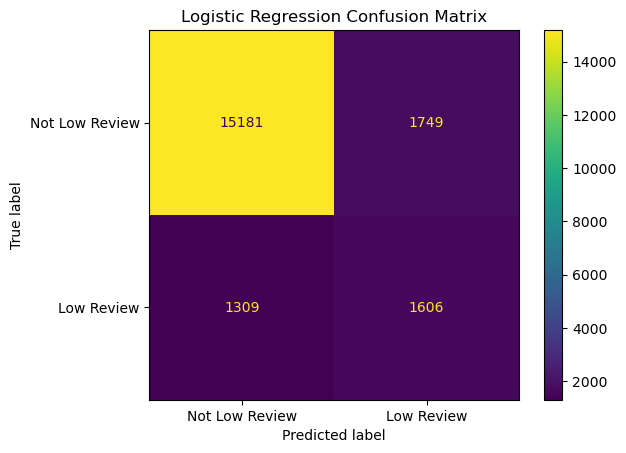

In [27]:
# Display Logistic Regression confusion matrix
cm_log_reg = confusion_matrix(y_test, log_reg_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_log_reg,
    display_labels=["Not Low Review", "Low Review"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## Step 5: Train and Evaluate Random Forest

A Random Forest model is also trained because it can capture more complex patterns than Logistic Regression. This is useful for customer satisfaction modeling because dissatisfaction may not come from one factor alone. For example, a customer may be more likely to leave a low review when a late delivery is combined with high freight cost, longer shipping time or multiple order items.

In [28]:
# Train Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Evaluate Random Forest model
rf_results, rf_pred = evaluate_classification_model(
    "Random Forest",
    rf_model,
    X_test,
    y_test
)

rf_results


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.90      0.91     16930
           1       0.48      0.56      0.52      2915

    accuracy                           0.85     19845
   macro avg       0.70      0.73      0.71     19845
weighted avg       0.86      0.85      0.85     19845



{'Model': 'Random Forest',
 'Accuracy': 0.8476190476190476,
 'Precision': 0.4838805087252292,
 'Recall': 0.5612349914236706,
 'F1 Score': 0.5196950444726811,
 'ROC-AUC': 0.7846156862228589}

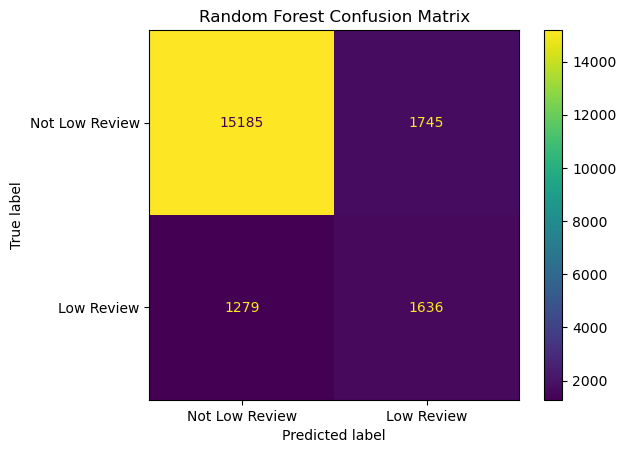

In [29]:
# Display Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Not Low Review", "Low Review"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

## Step 6: Compare Model Performance

The model results are compared side by side. This makes it easier to determine which model performs best and whether either machine learning model improves on the baseline Dummy Classifier.

In [30]:
# Combine model results into one comparison table
model_results = pd.DataFrame([
    dummy_results,
    log_reg_results,
    rf_results
])

# Round values for cleaner display
model_results_rounded = model_results.copy()
numeric_result_cols = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

for col in numeric_result_cols:
    model_results_rounded[col] = model_results_rounded[col].round(4)

display(model_results_rounded)

# Identify the best model by F1 Score
best_model_row = model_results.sort_values("F1 Score", ascending=False).iloc[0]

print("Best model based on F1 Score:")
print(best_model_row)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Dummy Classifier,0.8531,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.8459,0.4787,0.5509,0.5123,0.7843
2,Random Forest,0.8476,0.4839,0.5612,0.5197,0.7846


Best model based on F1 Score:
Model        Random Forest
Accuracy          0.847619
Precision         0.483881
Recall            0.561235
F1 Score          0.519695
ROC-AUC           0.784616
Name: 2, dtype: object


## Step 7: Review Important Predictors

For the Random Forest model, I review feature importance scores to better understand which variables contributed most to the model's predictions. This step supports interpretability and helps connect the model results back to the business problem.

,Feature,Importance
8,is_late,0.169211
7,delivery_delay_days,0.166275
15,order_status_delivered,0.153237
10,shipping_days,0.122507
5,days_to_deliver,0.101489
2,item_count,0.060209
18,order_status_shipped,0.035994
1,total_freight,0.028618
19,order_status_unavailable,0.023138
13,order_status_canceled,0.020199


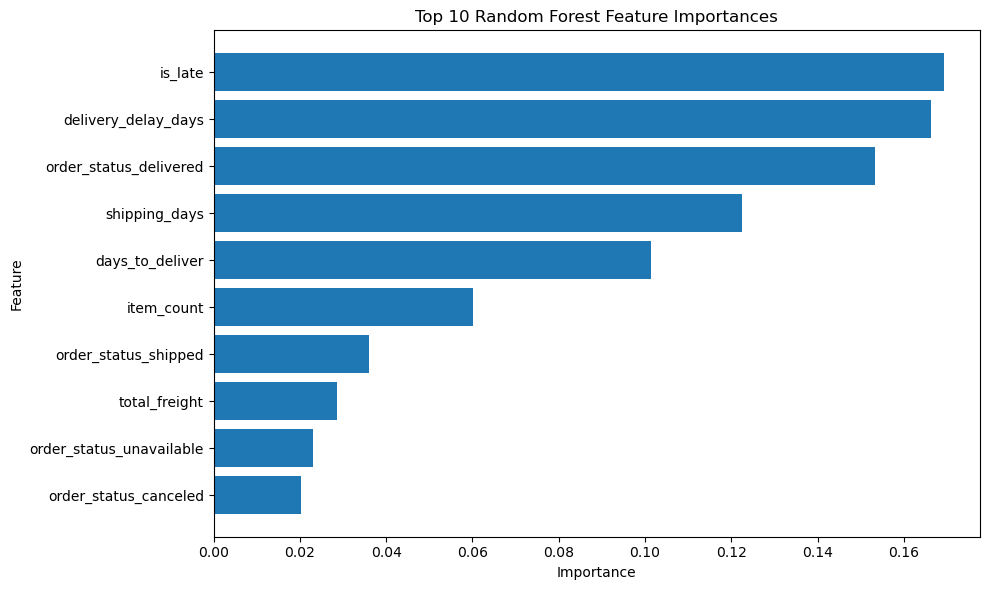

In [31]:
# Review top Random Forest feature importances
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(feature_importance.head(15))

# Plot the top 10 most important features
top_features = feature_importance.head(10).sort_values("Importance")

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Random Forest Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [32]:
# Generate a short model conclusion based on the comparison results
best_model_name = best_model_row["Model"]
best_f1 = best_model_row["F1 Score"]
best_recall = best_model_row["Recall"]
best_accuracy = best_model_row["Accuracy"]
best_roc_auc = best_model_row["ROC-AUC"]

print("Model Selection Summary")
print("-----------------------")
print(f"The best-performing model based on F1 Score was: {best_model_name}")
print(f"F1 Score: {best_f1:.4f}")
print(f"Recall: {best_recall:.4f}")
print(f"Accuracy: {best_accuracy:.4f}")
print(f"ROC-AUC: {best_roc_auc:.4f}")

print("\nInterpretation:")
print(
    f"Based on F1 Score, {best_model_name} is the strongest model for this milestone because "
    "it provides the best balance between identifying low-review orders and avoiding incorrect low-review predictions. "
    "This matters because the project goal is not only to make correct predictions overall, but also to identify dissatisfied customers more effectively."
)

Model Selection Summary
-----------------------
The best-performing model based on F1 Score was: Random Forest
F1 Score: 0.5197
Recall: 0.5612
Accuracy: 0.8476
ROC-AUC: 0.7846

Interpretation:
Based on F1 Score, Random Forest is the strongest model for this milestone because it provides the best balance between identifying low-review orders and avoiding incorrect low-review predictions. This matters because the project goal is not only to make correct predictions overall, but also to identify dissatisfied customers more effectively.


## Step 8: Model Building and Evaluation Conclusion

This milestone moved the project from data preparation into model building and evaluation. The target variable, `low_review`, was treated as a binary classification outcome because the project is focused on identifying orders that are more likely to receive poor customer feedback. The Dummy Classifier provided a baseline model and Logistic Regression and Random Forest provided more important machine learning approaches. Logistic Regression was useful because it's interpretable and appropriate for a first classification model. Random Forest was useful because it can capture nonlinear relationships between order, payment and delivery-related variables. After running the model comparison table, the notebook identifies the best-performing model based on **F1 Score**. I selected F1 Score as the primary comparison metric because it balances precision and recall, which is important when trying to identify lower-frequency negative customer experiences. The best model should not simply predict the majority class; it should help identify orders that are more likely to result in low customer reviews.

The most important insight I found from this milestone is that model evaluation shouldn't rely on accuracy alone. Since low reviews might be less common than positive reviews, a model can seem accurate while still failing to identify dissatisfied customers. For that reason, recall, F1 score and ROC-AUC are more useful for evaluating whether the model can support the business goal. This milestone shows that the Olist dataset can be used to build a predictive model for customer dissatisfaction. Improvements could include additional feature engineering, hyperparameter tuning, cross-validation and threshold adjustment to improve the model's ability to identify low-review orders before they become larger customer experience issues.

# Final Project Updates

The following content was added after Milestone 3 to satisfy the final project requirements.

## Final Model Comparison

Two machine learning models were evaluated to predict whether an e-commerce order would receive a low customer review score. Logistic Regression served as a strong baseline model due to its simplicity and interpretability. A Random Forest model was also trained to capture more complex nonlinear relationships among the features.

The Random Forest model achieved the strongest overall performance with an F1 Score of 0.5197, Recall of 0.5612, Accuracy of 0.8476, and ROC-AUC of 0.7846. Based on these metrics, Random Forest was selected as the preferred model.

## Business Interpretation

The model results indicate that operational factors are strongly associated with customer satisfaction. The most influential predictors identified by the Random Forest model were:

* Late delivery indicator (is_late)
* Delivery delay days
* Delivery status
* Shipping duration

These findings suggest that customer dissatisfaction is heavily influenced by delivery performance rather than simply the monetary value of an order.

## Deployment Assessment

Although the Random Forest model demonstrates promising predictive performance, it should not be deployed directly into production without additional validation. The model should first be evaluated using more recent data and monitored over time to ensure that performance remains stable.

Additional testing should also be performed to determine whether proactive interventions based on model predictions actually improve customer satisfaction outcomes.

## Recommendations

Based on the analysis and model results, the following recommendations are proposed:

1. Reduce late deliveries whenever possible.
2. Develop proactive customer outreach strategies for delayed orders.
3. Monitor product categories associated with lower customer satisfaction.
4. Incorporate predictive monitoring into operational dashboards.
5. Retrain the model periodically as customer behavior changes over time.

## Project Limitations

Several limitations should be acknowledged:

* Customer reviews are subjective and may be influenced by factors not captured in the dataset.
* The dataset represents historical transactions and may not reflect future customer behavior.
* Some variables that influence satisfaction may not be available within the dataset.
* Class imbalance remains a challenge because low-review orders occur less frequently.

## Future Opportunities

Several opportunities exist for extending this project:

* Incorporate natural language processing of written review comments.
* Add geographic and logistics variables.
* Evaluate additional machine learning algorithms such as XGBoost and LightGBM.
* Develop a real-time customer satisfaction prediction system.
* Create automated alerts for high-risk orders.

## Final Conclusion

This project successfully demonstrated how machine learning can be used to predict low customer review scores in an e-commerce environment. Exploratory data analysis showed strong relationships between delivery performance and customer satisfaction. Following extensive data preparation and feature engineering, multiple classification models were evaluated.

The Random Forest model achieved the strongest performance and identified delivery-related variables as the most important drivers of customer dissatisfaction. While additional validation is recommended prior to production deployment, the results demonstrate that predictive analytics can provide meaningful business value by helping organizations proactively identify at-risk customer experiences.
